# Chapitre 14 - Cours 2 : classification (analyse de groupements)

Ce notebook couvre la section 14.3 du livre (*cluster analysis*) :

1. matrices de proximité et dissimilarités entre objets ;
2. algorithmes combinatoires, **K-means** et lien avec les mélanges gaussiens ;
3. K-means sur les données de **micro-puces NCI** et quantification vectorielle ;
4. **K-médoïdes** sur les dissimilarités entre pays (figure 14.10) ;
5. choix du nombre de groupes et **statistique Gap** (figure 14.11) ;
6. **classification hiérarchique** et dendrogrammes sur les données NCI
   (figures 14.12 à 14.14).

Le mot anglais *clustering* sera traduit par « classification » (non supervisée) ou
« partitionnement » ; un *cluster* est un « groupe » ou une « classe ».

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from math import factorial
from scipy.special import comb
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS, decision_grid
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## 1. Objectifs de la classification

On veut regrouper $N$ objets en sous-ensembles (groupes) tels que les objets d'un même groupe
soient plus « proches » entre eux que d'objets de groupes différents. On peut aussi vouloir
organiser les groupes en **hiérarchie** (des groupes emboîtés dans des groupes).

Toute méthode repose sur une notion de **dissimilarité** entre objets. Comme le choix d'une
fonction de perte en apprentissage supervisé, ce choix vient de considérations extérieures
aux données (connaissance du domaine) et il est souvent plus important que l'algorithme
lui-même.

## 2. Matrices de proximité

Les données se présentent parfois directement sous forme d'une matrice $N \times N$
$\mathbf{D} = (d_{ii'})$ de dissimilarités : par exemple des jugements moyens d'étudiants sur la
ressemblance politique de pays (section 14.3.1). La plupart des algorithmes supposent

* $d_{ii'} \ge 0$ et $d_{ii} = 0$ ;
* $\mathbf{D}$ symétrique (sinon on la remplace par $(\mathbf{D} + \mathbf{D}^T)/2$).

Des dissimilarités subjectives ne vérifient pas forcément l'**inégalité triangulaire**
$d_{ii'} \le d_{ik} + d_{ki'}$ : ce ne sont pas toujours des distances au sens mathématique.

In [2]:
pays = datasets.load_countries()
Dp = pays.to_numpy()
noms_pays = list(pays.index)
print("Symétrique :", np.allclose(Dp, Dp.T), "; diagonale nulle :", np.all(np.diag(Dp) == 0))
viol = sum(Dp[i, j] > Dp[i, k] + Dp[k, j] + 1e-12
           for i in range(12) for j in range(12) for k in range(12))
print("Violations de l'inégalité triangulaire :", viol)
pays.round(2)

Symétrique : True ; diagonale nulle : True
Violations de l'inégalité triangulaire : 0


,BEL,BRA,CHI,CUB,EGY,FRA,IND,ISR,USA,USS,YUG,ZAI
BEL,0.00,5.58,7.00,7.08,4.83,2.17,6.42,3.42,2.50,6.08,5.25,4.75
BRA,5.58,0.00,6.50,7.00,5.08,5.75,5.00,5.50,4.92,6.67,6.83,3.00
CHI,7.00,6.50,0.00,3.83,8.17,6.67,5.58,6.42,6.25,4.25,4.50,6.08
CUB,7.08,7.00,3.83,0.00,5.83,6.92,6.00,6.42,7.33,2.67,3.75,6.67
EGY,4.83,5.08,8.17,5.83,0.00,4.92,4.67,5.00,4.50,6.00,5.75,5.00
FRA,2.17,5.75,6.67,6.92,4.92,0.00,6.42,3.92,2.25,6.17,5.42,5.58
IND,6.42,5.00,5.58,6.00,4.67,6.42,0.00,6.17,6.33,6.17,6.08,4.83
ISR,3.42,5.50,6.42,6.42,5.00,3.92,6.17,0.00,2.75,6.92,5.83,6.17
USA,2.50,4.92,6.25,7.33,4.50,2.25,6.33,2.75,0.00,6.17,6.67,5.67
USS,6.08,6.67,4.25,2.67,6.00,6.17,6.17,6.92,6.17,0.00,3.67,6.50


Ici (tableau 14.3 du livre), l'inégalité triangulaire est respectée, mais rien ne
l'imposait.

## 3. Dissimilarités construites à partir des variables

Le plus souvent on dispose de mesures $x_{ij}$ ($i = 1..N$ objets, $j = 1..p$ variables). On
définit une dissimilarité $d_j$ par variable et on les additionne (éq. (14.20)) :

$$D(x_i, x_{i'}) = \sum_{j=1}^p d_j(x_{ij}, x_{i'j}).$$

Le choix le plus courant est le carré de l'écart, $d_j(x_{ij}, x_{i'j}) = (x_{ij} -
x_{i'j})^2$ (14.21), ce qui donne le carré de la distance euclidienne.

Selon le **type** de variable :

* **quantitative** : $(x_{ij} - x_{i'j})^2$ ou $|x_{ij} - x_{i'j}|$ ;
* **ordinale** à $M$ niveaux : on remplace le niveau $i$ par le score $\frac{i - 1/2}{M}$
  (éq. (14.23)) puis on la traite comme quantitative ;
* **catégorielle** à $M$ modalités : on se donne une matrice $M \times M$ de pertes $L_{rr'}$
  symétrique, nulle sur la diagonale ; le choix le plus simple est $L_{rr'} = 1$ si $r \ne r'$.

### Corrélation et distance euclidienne

On utilise parfois la **corrélation** entre deux objets (calculée sur leurs $p$ variables),
éq. (14.22) :

$$\rho(x_i, x_{i'}) = \frac{\sum_j (x_{ij} - \bar x_i)(x_{i'j} - \bar x_{i'})}
{\sqrt{\sum_j (x_{ij} - \bar x_i)^2 \sum_j (x_{i'j} - \bar x_{i'})^2}},
\qquad \bar x_i = \frac1p \sum_j x_{ij}.$$

**Propriété.** Si chaque objet est **standardisé** ($\bar x_i = 0$ et $\sum_j x_{ij}^2 = 1$), alors
$\sum_j (x_{ij} - x_{i'j})^2 = 2\,(1 - \rho(x_i, x_{i'}))$.

*Preuve.* On développe le carré :
$\sum_j (x_{ij} - x_{i'j})^2 = \sum_j x_{ij}^2 + \sum_j x_{i'j}^2 - 2 \sum_j x_{ij} x_{i'j}$.
Les deux premiers termes valent 1 par standardisation, et comme les moyennes sont nulles et
les normes égales à 1, $\rho(x_i, x_{i'}) = \sum_j x_{ij} x_{i'j}$. D'où $2 - 2\rho$. $\square$

Classer selon la corrélation revient donc à classer selon la distance euclidienne d'objets
standardisés. Vérification numérique :

In [3]:
rng = np.random.RandomState(0)
A = rng.normal(size=(2, 30))
As = (A - A.mean(1, keepdims=True))
As /= np.sqrt((As ** 2).sum(1, keepdims=True))
print("somme des carrés :", ((As[0] - As[1]) ** 2).sum())
print("2 (1 - rho)      :", 2 * (1 - np.corrcoef(A)[0, 1]))

somme des carrés : 2.4259383568754296
2 (1 - rho)      : 2.42593835687543


## 4. Pondération des variables : le piège de la standardisation

On peut pondérer les variables (éq. (14.24)) : $D(x_i, x_{i'}) = \sum_j w_j\, d_j(x_{ij},
x_{i'j})$ avec $\sum_j w_j = 1$. Mais l'**influence** d'une variable ne dépend pas que de son
poids : elle dépend aussi de la dissimilarité moyenne

$$\bar d_j = \frac{1}{N^2} \sum_{i=1}^N \sum_{i'=1}^N d_j(x_{ij}, x_{i'j}) \qquad (14.25).$$

L'influence relative de la variable $j$ sur la dissimilarité moyenne entre objets est
$w_j \bar d_j$.

**Calcul de $\bar d_j$ pour le carré de l'écart.** Notons $\bar x_j$ la moyenne de la colonne
$j$. On écrit $x_{ij} - x_{i'j} = (x_{ij} - \bar x_j) - (x_{i'j} - \bar x_j)$ et on développe :

$$\frac{1}{N^2}\sum_{i,i'} (x_{ij} - x_{i'j})^2
  = \frac{1}{N}\sum_i (x_{ij} - \bar x_j)^2 + \frac{1}{N}\sum_{i'} (x_{i'j} - \bar x_j)^2
  - \frac{2}{N^2} \Big(\sum_i (x_{ij} - \bar x_j)\Big)\Big(\sum_{i'} (x_{i'j} - \bar x_j)\Big).$$

Le dernier produit est nul (somme des écarts à la moyenne), d'où
$\bar d_j = 2\,\mathrm{var}_j$ (éq. (14.27)), avec $\mathrm{var}_j$ la variance empirique
(normalisée par $N$).

In [4]:
x = rng.normal(size=50) * 3
print("dbar_j    :", np.mean((x[:, None] - x[None, :]) ** 2))
print("2 * var_j :", 2 * x.var())

dbar_j    : 19.243234959052344
2 * var_j : 19.243234959052348


Prendre $w_j = 1/\bar d_j$ donne donc la même influence à toutes les variables : c'est la
**standardisation** des variables. C'est souvent recommandé, mais cela peut être
**contre-productif** : si une variable a une grande variance *parce qu'elle sépare les
groupes*, la standardiser revient à réduire cette séparation. Illustration (analogue de la
figure 14.5) : deux groupes bien séparés selon $X_1$, l'un étant très allongé selon $X_2$.

In [5]:
rng = np.random.RandomState(0)
n = 100
Xs5 = np.vstack([rng.normal(size=(n, 2)) @ np.array([[0.5, 2.6], [-1.2, 0.2]]) + [-3, 0],
                 rng.normal(size=(n, 2)) @ np.diag([0.5, 0.8]) + [3, 0.5]])
y5 = np.r_[np.zeros(n), np.ones(n)]
lab_brut = ns.kmeans(Xs5, 2, rng=rng)[0]
Xstd = (Xs5 - Xs5.mean(0)) / Xs5.std(0)
lab_std = ns.kmeans(Xstd, 2, rng=rng)[0]
print("écarts-types des variables :", Xs5.std(0).round(2))
print("Rand ajusté, données brutes       : %.2f" % ns.indice_rand_ajuste(lab_brut, y5))
print("Rand ajusté, données standardisées : %.2f" % ns.indice_rand_ajuste(lab_std, y5))

écarts-types des variables : [3.21 1.96]
Rand ajusté, données brutes       : 0.96
Rand ajusté, données standardisées : 0.41


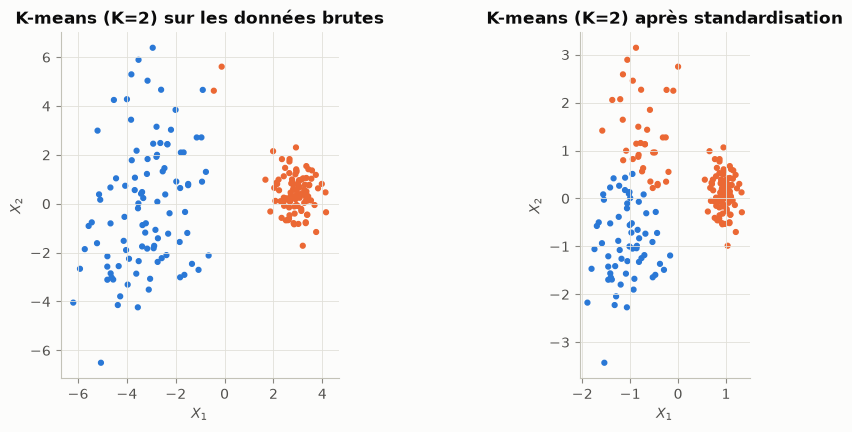

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, Xp, lab, titre in ((axes[0], Xs5, lab_brut, "K-means (K=2) sur les données brutes"),
                           (axes[1], Xstd, lab_std, "K-means (K=2) après standardisation")):
    ax.scatter(*Xp.T, c=[COLORS[k] for k in lab], s=12)
    ax.set_aspect("equal")
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_title(titre)
plt.show()

Après standardisation, $X_1$ (dont la variance vient surtout de l'écart entre les groupes) est
fortement contractée et $X_2$ dilatée : K-means coupe alors le groupe allongé.

> **À retenir.** Les poids des variables doivent refléter ce qui compte pour la
> ressemblance entre objets. Une standardisation systématique n'est pas neutre : elle impose
> à toutes les variables la même influence, ce qui peut masquer les groupes.

## 5. Algorithmes combinatoires

Un algorithme de classification attribue à chaque observation $i$ un groupe $k = C(i) \in
\{1, \dots, K\}$ ; l'application $C$ s'appelle l'**encodeur**. On cherche à minimiser la
**dispersion intra-groupes** (éq. (14.28))

$$W(C) = \frac12 \sum_{k=1}^K \sum_{C(i)=k} \sum_{C(i')=k} d(x_i, x_{i'}).$$

La **dispersion totale** $T = \frac12 \sum_{i,i'} d_{ii'}$ ne dépend pas de $C$. En séparant les
paires de même groupe et de groupes différents,

$$T = W(C) + B(C), \qquad B(C) = \frac12 \sum_{k=1}^K \sum_{C(i)=k} \sum_{C(i') \ne k} d_{ii'}
\quad (14.29).$$

Minimiser $W(C)$ revient donc à **maximiser** la dispersion inter-groupes $B(C)$.

On pourrait en principe essayer tous les encodeurs. Leur nombre est le nombre de Stirling de
seconde espèce (éq. (14.30)) :

$$S(N, K) = \frac{1}{K!} \sum_{k=1}^K (-1)^{K-k} \binom{K}{k} k^N .$$

In [7]:
def stirling2(N, K):
    return sum((-1) ** (K - k) * comb(K, k, exact=True) * k ** N for k in range(1, K + 1)) // factorial(K)


for N_ in (10, 19, 50, 100):
    print("S(%3d, 4) = %.4g" % (N_, stirling2(N_, 4)))

S( 10, 4) = 3.41e+04
S( 19, 4) = 1.126e+10
S( 50, 4) = 5.282e+28
S(100, 4) = 6.696e+58


Déjà $S(19, 4) \approx 10^{10}$ : l'énumération est impossible. On utilise des
**descentes itératives** (« greedy ») qui modifient l'encodeur pour faire décroître $W(C)$,
au risque de s'arrêter dans un minimum local.

## 6. K-means

### 6.1 Le critère

Avec le carré de la distance euclidienne, le critère prend une forme simple. Notons
$N_k$ l'effectif du groupe $k$ et $\bar x_k$ sa moyenne. Pour un groupe fixé, en écrivant
$x_i - x_{i'} = (x_i - \bar x_k) - (x_{i'} - \bar x_k)$ et en développant comme au §4,

$$\frac12 \sum_{C(i)=k}\sum_{C(i')=k} \|x_i - x_{i'}\|^2 = N_k \sum_{C(i)=k} \|x_i - \bar x_k\|^2,$$

d'où $W(C) = \sum_k N_k \sum_{C(i)=k} \|x_i - \bar x_k\|^2$ (éq. (14.31)).

**Lemme (la moyenne minimise l'inertie).** Pour tout ensemble $S$ de points,
$\bar x_S = \operatorname{argmin}_m \sum_{i \in S} \|x_i - m\|^2$ (éq. (14.32)).

*Preuve.* $\sum_{i \in S} \|x_i - m\|^2 = \sum_{i\in S} \|x_i - \bar x_S\|^2 + |S|\,\|\bar x_S -
m\|^2$ (on développe $x_i - m = (x_i - \bar x_S) + (\bar x_S - m)$, le terme croisé est nul car
$\sum_{i\in S} (x_i - \bar x_S) = 0$). Le second terme est minimal, nul, pour $m = \bar x_S$.
$\square$

On peut donc écrire le problème avec des centres $m_k$ libres (éq. (14.33)) :

$$\min_{C,\, \{m_k\}} \; \sum_{k=1}^K N_k \sum_{C(i)=k} \|x_i - m_k\|^2 .$$

En pratique (et dans `ns.kmeans`, comme dans la plupart des logiciels), on minimise la somme
des carrés intra-groupes $\sum_k \sum_{C(i)=k} \|x_i - m_k\|^2$, sans le facteur $N_k$ ;
l'algorithme est le même.

### 6.2 L'algorithme (algorithme 14.1 du livre)

1. À encodeur $C$ fixé, chaque centre $m_k$ devient la moyenne de son groupe (lemme).
2. À centres fixés, chaque observation est affectée au centre le plus proche :
   $C(i) = \operatorname{argmin}_k \|x_i - m_k\|^2$ (éq. (14.34)).
3. On répète jusqu'à ce que les affectations ne changent plus.

Chaque étape fait décroître (au sens large) le critère, qui ne peut prendre qu'un nombre fini
de valeurs : l'algorithme **converge** en un nombre fini d'itérations, vers un minimum
**local**. On le relance donc depuis plusieurs initialisations aléatoires.

### 6.3 Données simulées (figures 14.4 et 14.6)

Trois groupes dans le plan, dont deux mal séparés.

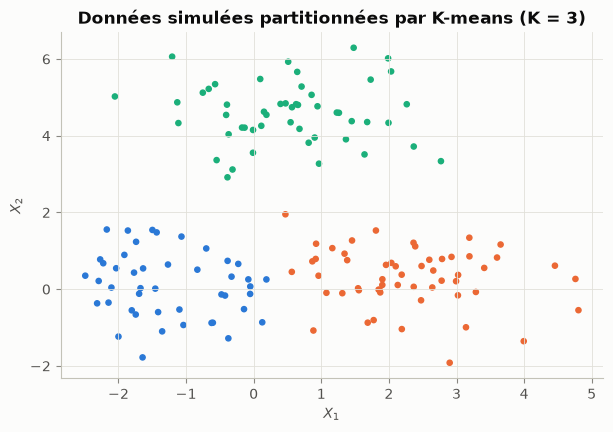

In [8]:
rng = np.random.RandomState(0)
centres_vrais = np.array([[0.5, 4.5], [-1.0, 0.0], [2.5, 0.3]])
X4 = np.vstack([rng.normal(c, [1.0, 0.8], size=(50, 2)) for c in centres_vrais])
y4 = np.repeat([0, 1, 2], 50)
lab4, C4, W4 = ns.kmeans(X4, 3, n_init=10, rng=rng)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(*X4.T, c=[COLORS[k] for k in lab4], s=14)
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_title("Données simulées partitionnées par K-means (K = 3)")
plt.show()

Suivons maintenant les itérations de l'algorithme à partir de trois centres initiaux tirés au
hasard. Les zones colorées forment la **tessellation de Voronoï** : chaque zone est l'ensemble
des points plus proches d'un centre que des autres.

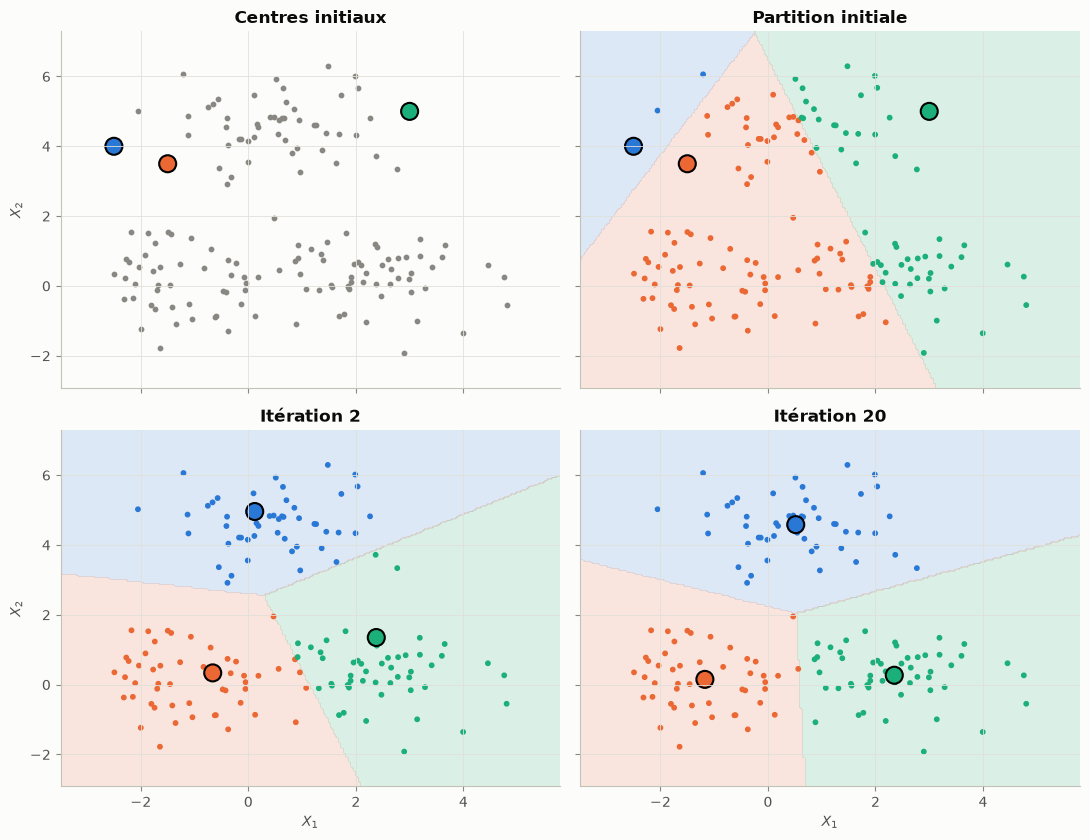

In [9]:
def iterations_kmeans(X, C0, n_iter):
    C = C0.copy()
    etats = [(C.copy(), ns.distances_carrees(X, C).argmin(1))]
    for _ in range(n_iter):
        lab = ns.distances_carrees(X, C).argmin(1)
        C = np.array([X[lab == k].mean(0) for k in range(len(C))])
        etats.append((C.copy(), ns.distances_carrees(X, C).argmin(1)))
    return etats


C0 = np.array([[-2.5, 4.0], [-1.5, 3.5], [3.0, 5.0]])
etats = iterations_kmeans(X4, C0, 20)
xx, yy, grille = decision_grid((X4[:, 0].min() - 1, X4[:, 0].max() + 1),
                               (X4[:, 1].min() - 1, X4[:, 1].max() + 1), 200)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
panneaux = [(0, "Centres initiaux", False), (0, "Partition initiale", True),
            (2, "Itération 2", True), (20, "Itération 20", True)]
for ax, (t, titre, colorer) in zip(axes.ravel(), panneaux):
    C, lab = etats[t]
    if colorer:
        zone = ns.distances_carrees(grille, C).argmin(1).reshape(xx.shape)
        ax.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=COLORS[:3], alpha=0.15)
        ax.scatter(*X4.T, c=[COLORS[k] for k in lab], s=10)
    else:
        ax.scatter(*X4.T, color=GRAY, s=10)
    ax.scatter(*C.T, c=COLORS[:3], s=150, marker="o", edgecolor="k", linewidth=1.5)
    ax.set_title(titre)
for ax in axes[1]:
    ax.set_xlabel("$X_1$")
for ax in axes[:, 0]:
    ax.set_ylabel("$X_2$")
plt.tight_layout()
plt.show()

Vérifions que le critère décroît à chaque itération.

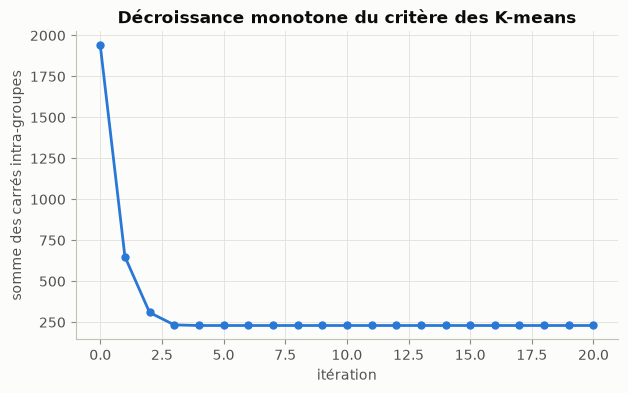

In [10]:
crit = [((X4 - C[lab]) ** 2).sum() for C, lab in etats]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(len(crit)), crit, "o-", color=BLUE)
ax.set_xlabel("itération")
ax.set_ylabel("somme des carrés intra-groupes")
ax.set_title("Décroissance monotone du critère des K-means")
plt.show()

### 6.4 Mélanges gaussiens : des K-means « doux » (section 14.3.7, figure 14.7)

Considérons un mélange de $K$ gaussiennes de même covariance $\sigma^2 I$. L'algorithme EM
(section 8.5) calcule à l'étape E les **responsabilités**

$$\hat\gamma_{ik} = \frac{\pi_k\, \phi_\sigma(x_i - \mu_k)}{\sum_l \pi_l\, \phi_\sigma(x_i - \mu_l)},
\qquad \phi_\sigma(u) \propto e^{-\|u\|^2/(2\sigma^2)},$$

fonctions décroissantes de la distance de $x_i$ à chaque centre : c'est une affectation
« douce ». Quand $\sigma \to 0$, la responsabilité du centre le plus proche tend vers 1 et les
autres vers 0 : on retrouve l'affectation « dure » des K-means (exercice 14.2).

sigma = 1.0 : responsabilités en x = 0,5 : 0.269 et 0.731
sigma = 0.2 : responsabilités en x = 0,5 : 0.000 et 1.000


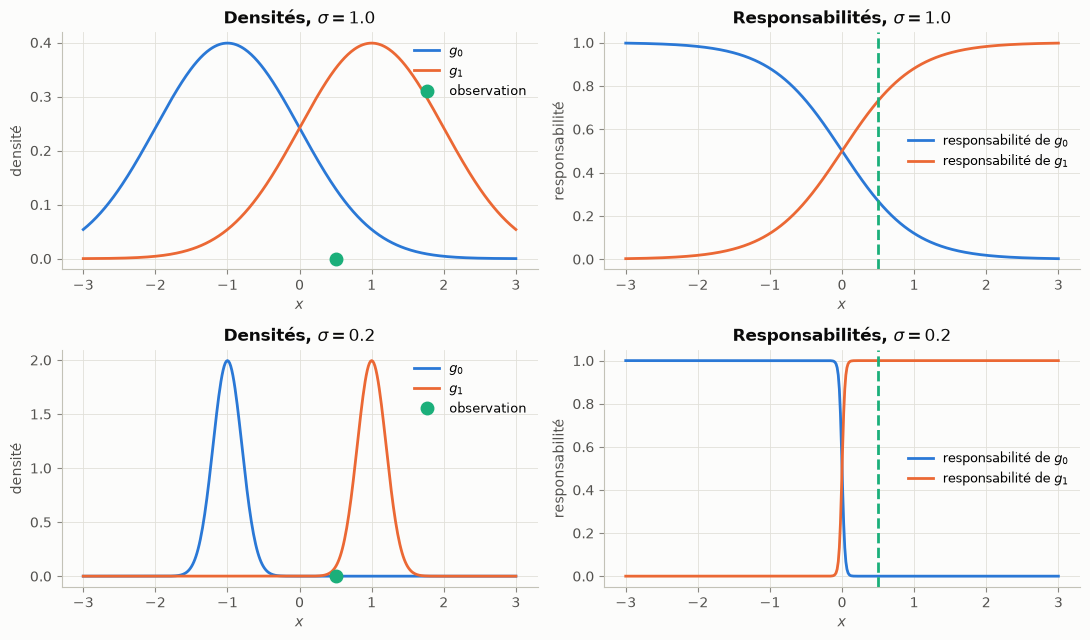

In [11]:
xg = np.linspace(-3, 3, 400)
x_obs = 0.5
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ligne, sigma in enumerate((1.0, 0.2)):
    g0 = np.exp(-(xg + 1) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))
    g1 = np.exp(-(xg - 1) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))
    ax = axes[ligne, 0]
    ax.plot(xg, g0, color=BLUE, label="$g_0$")
    ax.plot(xg, g1, color=ORANGE, label="$g_1$")
    ax.plot([x_obs], [0], "o", color=COLORS[2], ms=9, label="observation")
    ax.set_title("Densités, $\\sigma = %.1f$" % sigma)
    ax.set_xlabel("$x$")
    ax.set_ylabel("densité")
    ax.legend()
    ax = axes[ligne, 1]
    r1 = g1 / (g0 + g1)
    ax.plot(xg, 1 - r1, color=BLUE, label="responsabilité de $g_0$")
    ax.plot(xg, r1, color=ORANGE, label="responsabilité de $g_1$")
    ax.axvline(x_obs, color=COLORS[2], ls="--")
    ax.set_title("Responsabilités, $\\sigma = %.1f$" % sigma)
    ax.set_xlabel("$x$")
    ax.set_ylabel("responsabilité")
    ax.legend(loc="center right")
    r_obs = 1 / (1 + np.exp(-2 * x_obs / sigma ** 2))
    print("sigma = %.1f : responsabilités en x = 0,5 : %.3f et %.3f" % (sigma, 1 - r_obs, r_obs))
plt.tight_layout()
plt.show()

Pour $\sigma = 1$ l'observation est partagée entre les deux groupes ; pour $\sigma = 0{,}2$
elle est attribuée presque sûrement au groupe le plus proche.

## 7. Exemple : micro-puces de tumeurs humaines (section 14.3.8)

Les données NCI60 forment une matrice de 6830 gènes × 64 échantillons (lignées cellulaires
cancéreuses). On classe ici les **échantillons**, chacun étant un vecteur de $\mathbb{R}^{6830}$ ;
leurs étiquettes (type de cancer) ne servent qu'à interpréter les groupes a posteriori.

In [12]:
Xnci, types = datasets.load_nci()
print("Échantillons × gènes :", Xnci.shape)
pd.Series(types).value_counts()

Échantillons × gènes : (64, 6830)


RENAL          9
NSCLC          9
MELANOMA       8
BREAST         7
COLON          7
OVARIAN        6
LEUKEMIA       6
CNS            5
PROSTATE       2
UNKNOWN        1
K562B-repro    1
K562A-repro    1
MCF7A-repro    1
MCF7D-repro    1
Name: count, dtype: int64

Figure 14.8 : somme des carrés intra-groupes en fonction de $K$.

In [ ]:
Ks = np.arange(1, 11)
W_nci = [ns.kmeans(Xnci, K, n_init=10, rng=np.random.RandomState(0))[2] for K in Ks]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(Ks, W_nci, "o-", color=BLUE)
ax.set_xlabel("nombre de groupes $K$")
ax.set_ylabel("somme des carrés intra-groupes")
ax.set_title("K-means sur les données NCI (figure 14.8)")
plt.show()

Comme dans le livre, la courbe ne présente pas de « coude » net. On retient $K = 3$ pour
l'illustration (tableau 14.2) :

In [ ]:
lab_nci3 = ns.kmeans(Xnci, 3, n_init=20, rng=np.random.RandomState(0))[0]
pd.crosstab(pd.Series(lab_nci3, name="groupe"), pd.Series(types, name="type"))

Les échantillons d'un même cancer tombent en grande partie dans le même groupe (mélanomes,
leucémies, côlon, rein…). Deux défauts des K-means apparaissent toutefois :

* aucun **ordre** à l'intérieur d'un groupe ;
* quand $K$ change, les groupes peuvent changer de façon arbitraire : ils ne sont pas
  **emboîtés**. La classification hiérarchique (§11) corrige ces deux points.